In [1]:
# === SETTINGS ===
%config InlineBackend.figure_format = 'svg'
import numpy as np

from parity_lib import (
    apply_pub_style,
    analyze_file,
    select_theta_opt, select_big_small,
    extract_quadratures_fit, extract_quadratures_exp,
    fidelity_two_basis, fidelity_three_basis, correlator_per_basis,
    create_figure,
    COLORS_PARITY, COLORS_BAR,
)
apply_pub_style()

# ---- DATA FILES (set FILE_Y / QWP_Y to enable three-basis fidelity) ----
FILE_Z = "/Users/faaisalherzallah/Faisal/Research/Atom Photon Entanglement Analysis/After swap/Z_basis_parity_measurement_Optimized_20260417_1501.csv"
FILE_X = "/Users/faaisalherzallah/Faisal/Parity Oscillations/X_basis_parity_measurement_Optimized_20260426_0826.csv"
#FILE_Y = None  # e.g. "/Users/faaisalherzallah/Faisal/Parity Oscillations/Y_basis_parity_measurement_Optimized_20260420_1807.csv"
FILE_Y = "/Users/faaisalherzallah/Faisal/Bell State Tomography/Data/Y_basis_parity_measurement_Optimized_20260420_1807.csv"

QWP_Z = 182.5
QWP_X = 91
#QWP_Y = None   # set after running parity_osc.ipynb on the Y file to pick the best QWP
QWP_Y = 50

HIST_THRES = 15

# ---- PER-BASIS LATEX LABELS ----
# Bar order is fixed by the analysis: vals = [p_S1_L, p_S0_L, p_S1_E, p_S0_E].
# The user can override per-basis labels here; the photon basis differs across rows.
LBL_CATS = {
    'Z': [r"$|\uparrow'\rangle|V\rangle$", r"$|\uparrow'\rangle|H\rangle$",
          r"$|\downarrow\rangle|V\rangle$", r"$|\downarrow\rangle|H\rangle$"],
    'X': [r"$|\uparrow'\rangle|V\rangle$", r"$|\uparrow'\rangle|H\rangle$",
          r"$|\downarrow\rangle|V\rangle$", r"$|\downarrow\rangle|H\rangle$"],
    # Y bar labels: replace ? with R/L (circular) or D/A (diagonal) per your analyzer setting.
    'Y': [r"$|\uparrow'\rangle|?\rangle$", r"$|\uparrow'\rangle|?\rangle$",
          r"$|\downarrow\rangle|?\rangle$", r"$|\downarrow\rangle|?\rangle$"],
}
LBL_PARITY_A = {
    'Z': r"$|\uparrow'\rangle|H\rangle + |\downarrow\rangle|V\rangle$",
    'X': r"$|\uparrow'\rangle|H\rangle + |\downarrow\rangle|V\rangle$",
    'Y': r"$|\uparrow'\rangle|?\rangle + |\downarrow\rangle|?\rangle$",
}
LBL_PARITY_B = {
    'Z': r"$|\uparrow'\rangle|V\rangle + |\downarrow\rangle|H\rangle$",
    'X': r"$|\uparrow'\rangle|V\rangle + |\downarrow\rangle|H\rangle$",
    'Y': r"$|\uparrow'\rangle|?\rangle + |\downarrow\rangle|?\rangle$",
}

# Active bases (Y included only when both FILE_Y and QWP_Y are set)
BASES = [
    ('Z', FILE_Z, QWP_Z),
    ('X', FILE_X, QWP_X),
    ('Y', FILE_Y, QWP_Y),
]
BASES = [(b, f, q) for (b, f, q) in BASES if f is not None and q is not None]
BASIS_ORDER = tuple(b for b, _, _ in BASES)
print(f"Active bases: {BASIS_ORDER}")


Active bases: ('Z', 'X', 'Y')


In [2]:
# === RUN: load + per-QWP analysis for each basis ===
analyzed = {}
for basis, file_path, qwp in BASES:
    data = analyze_file(file_path, qwp, HIST_THRES)
    if data is None:
        raise SystemExit(f"Failed to load {basis}-basis from {file_path} at QWP={qwp}")
    analyzed[basis] = data
    print(f"{basis}-basis loaded (QWP={qwp}): {len(data['angles'])} HWP angles, "
          f"vis_plus={data['fits']['parity_plus']['vis']:.3f}, "
          f"vis_minus={data['fits']['parity_minus']['vis']:.3f}")


Z-basis loaded (QWP=182.5): 9 HWP angles, vis_plus=0.826, vis_minus=0.920
X-basis loaded (QWP=91): 9 HWP angles, vis_plus=0.831, vis_minus=0.896
Y-basis loaded (QWP=50): 9 HWP angles, vis_plus=0.843, vis_minus=0.877


In [3]:
# === COMPUTE: per-basis theta_opt, quadratures, fidelity (fit and experimental) ===
def build_per_basis(use_fits: bool):
    out = {}
    for basis in BASIS_ORDER:
        data = analyzed[basis]
        th, idx, plus_dom = select_theta_opt(data, use_fits=use_fits)
        if use_fits:
            vals, errs = extract_quadratures_fit(th, data['fits'])
        else:
            vals, errs = extract_quadratures_exp(idx, data['res'])
        big_idx, small_idx = select_big_small(plus_dom)
        out[basis] = dict(
            analyze=data, theta_opt=th, vals=vals, errs=errs,
            big_idx=big_idx, small_idx=small_idx,
            plus_dominant=plus_dom,
            colors_parity=COLORS_PARITY[basis],
            color_bar=COLORS_BAR[basis],
            lbl_cats=LBL_CATS[basis],
            lbl_parity_a=LBL_PARITY_A[basis],
            lbl_parity_b=LBL_PARITY_B[basis],
        )
    return out

per_fit = build_per_basis(use_fits=True)
per_exp = build_per_basis(use_fits=False)

def compute_fidelity(per):
    if 'Y' in per:
        F, sF = fidelity_three_basis(per)
        return F, sF, 'equal'
    F, sF = fidelity_two_basis(
        per['Z']['vals'], per['Z']['errs'], per['X']['vals'], per['X']['errs'],
        big_idx_z=per['Z']['big_idx'], small_idx_z=per['Z']['small_idx'],
        big_idx_x=per['X']['big_idx'], small_idx_x=per['X']['small_idx'],
    )
    return F, sF, 'lower'

F_fit, sF_fit, mode_fit = compute_fidelity(per_fit)
F_exp, sF_exp, mode_exp = compute_fidelity(per_exp)

print(f"F_fit = {F_fit:.4f} ± {sF_fit:.4f}  ({'F = ...' if mode_fit=='equal' else 'F >= ...'})")
print(f"F_exp = {F_exp:.4f} ± {sF_exp:.4f}  ({'F = ...' if mode_exp=='equal' else 'F >= ...'})")

if 'Y' in per_fit:
    print("\nPer-basis correlator contributions (fit):")
    for k, (c, s) in correlator_per_basis(per_fit).items():
        print(f"  {k}: {c:+.4f} ± {s:.4f}")

# Pick the better mode for the clean (no-title) version
use_fit_for_clean = F_fit >= F_exp


F_fit = 0.9219 ± 0.0178  (F = ...)
F_exp = 0.9100 ± 0.0322  (F = ...)

Per-basis correlator contributions (fit):
  Z: +0.9142 ± 0.0425
  X: +0.9088 ± 0.0388
  Y: +0.8645 ± 0.0420


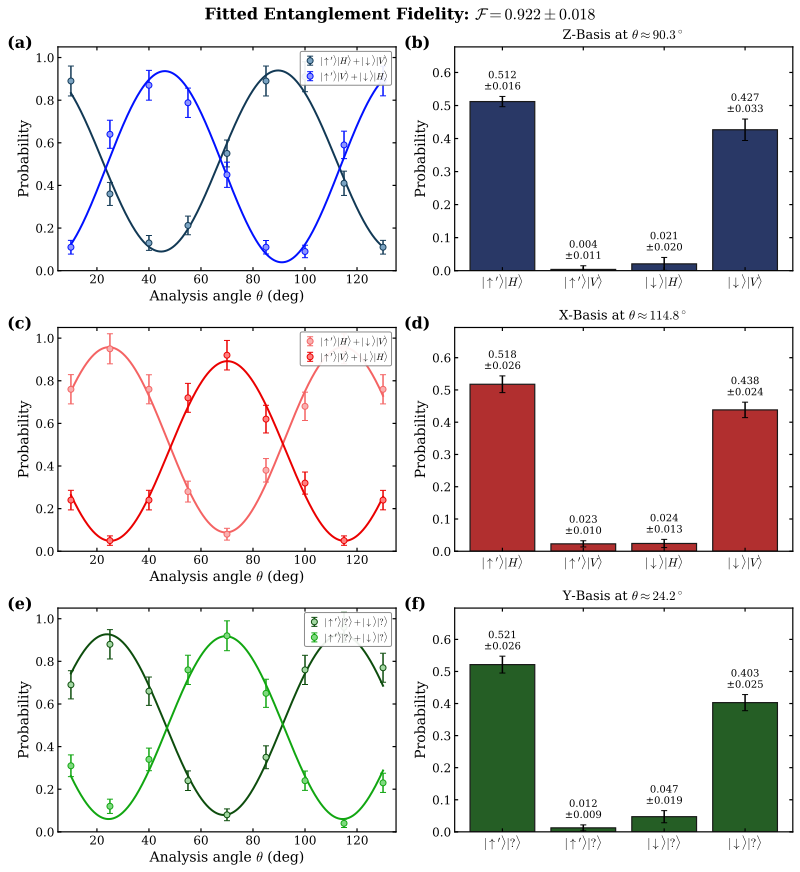

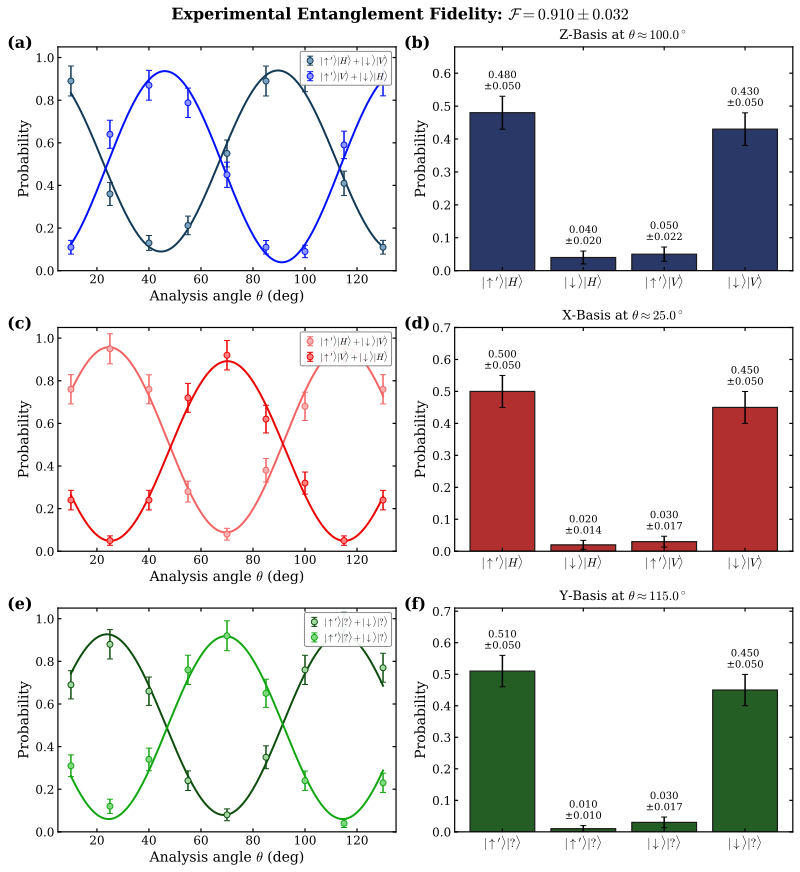

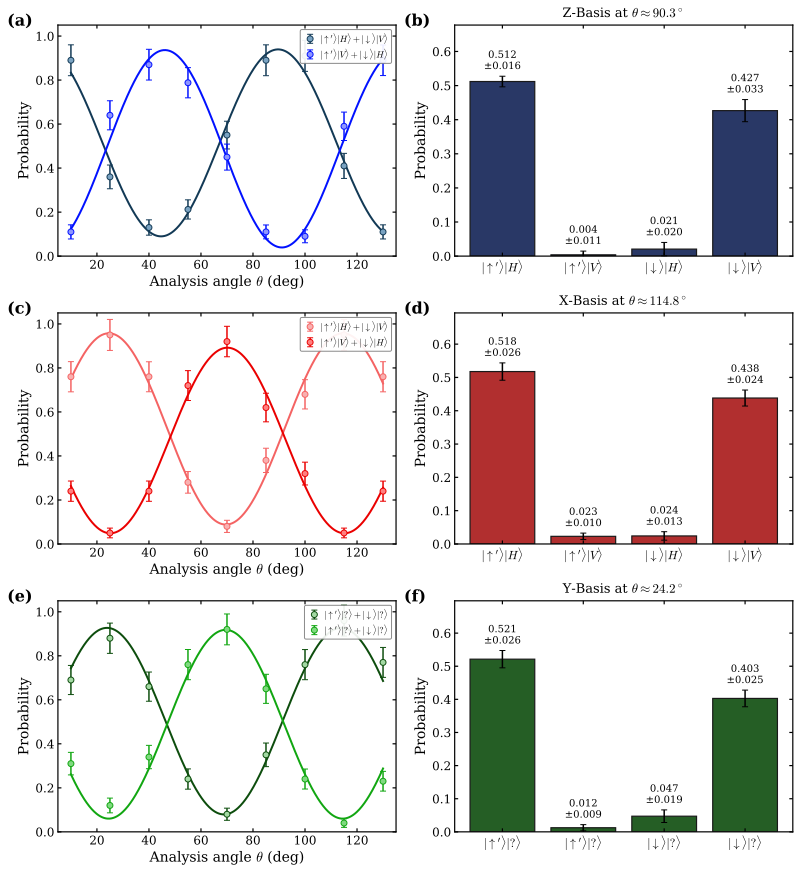

In [4]:
# === PLOT: three figures (fitted, experimental, best-clean) ===
create_figure(per_fit, basis_order=BASIS_ORDER,
              fid=F_fit, fid_err=sF_fit, fid_mode=mode_fit,
              use_fits=True, filename="parity_figure_fitted.svg",
              show_title=True)

create_figure(per_exp, basis_order=BASIS_ORDER,
              fid=F_exp, fid_err=sF_exp, fid_mode=mode_exp,
              use_fits=False, filename="parity_figure_experimental.svg",
              show_title=True)

if use_fit_for_clean:
    create_figure(per_fit, basis_order=BASIS_ORDER,
                  fid=F_fit, fid_err=sF_fit, fid_mode=mode_fit,
                  use_fits=True, filename="parity_figure_best_clean.svg",
                  show_title=False)
else:
    create_figure(per_exp, basis_order=BASIS_ORDER,
                  fid=F_exp, fid_err=sF_exp, fid_mode=mode_exp,
                  use_fits=False, filename="parity_figure_best_clean.svg",
                  show_title=False)
